# Titanic: Naive Bayes and Logistic Regression
**Objective:** prepare the data, train two classifiers, and compare their results.
Positive class: `Survived = 1`. This is a beginner assignment with default models.
No parameter search, resampling, or advanced model engineering is used.

## 1. Import libraries
pandas handles tables, matplotlib draws graphs, and scikit-learn supplies the models.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix, ConfusionMatrixDisplay)

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent  # also allows running from notebooks/
REPORTS = ROOT / "reports"
(REPORTS / "figures").mkdir(parents=True, exist_ok=True)

## 2. Load the data
Source: [Kaggle Titanic competition](https://www.kaggle.com/competitions/titanic/data).
Read only the labeled `train.csv` from the supplied ZIP. Kaggle's `test.csv` has
no survival labels; `gender_submission.csv` contains example predictions, not truth.
The checksum confirms that we use the same original file each time.

In [2]:
with ZipFile(ROOT / "data" / "titanic.zip") as archive:
    raw_csv = archive.read("train.csv")
expected_hash = "7d118fef8b6ccf7f81111877bc388536f7b1e498a655e3d649d19aaa010e9f6f"
assert hashlib.sha256(raw_csv).hexdigest() == expected_hash, "Unexpected dataset version"
df = pd.read_csv(BytesIO(raw_csv))
print("Rows and columns:", df.shape)
print(df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"]).head().to_string(index=False))

Rows and columns: (891, 12)
 Survived  Pclass    Sex  Age  SibSp  Parch    Fare Embarked
        0       3   male 22.0      1      0  7.2500        S
        1       1 female 38.0      1      0 71.2833        C
        1       3 female 26.0      0      0  7.9250        S
        1       1 female 35.0      1      0 53.1000        S
        0       3   male 35.0      0      0  8.0500        S


## 3. Inspect data quality
Check types, missing values, duplicates, class counts and numeric ranges.
No records are removed. Zero and high fares are kept because they are not proven errors.

In [3]:
print("Column types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate passenger IDs:", df.PassengerId.duplicated().sum())
print("\nClass counts (0=no, 1=yes):\n", df.Survived.value_counts())
print("\nNumeric summary:\n", df[["Age", "SibSp", "Parch", "Fare"]].describe())
df.isna().sum().rename("missing_records").to_csv(REPORTS / "missing_values.csv")

Column types:
 PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Duplicate rows: 0
Duplicate passenger IDs: 0

Class counts (0=no, 1=yes):
 Survived
0    549
1    342
Name: count, dtype: int64

Numeric summary:
               Age       SibSp       Parch        Fare
count  714.000000  891.000000  891.000000  891.000000
mean    29.699118    0.523008    0.381594   32.204208
std     14.526497    1.102743    0.806057   49.693429
min      0.420000    0.000000    0.000000    0.000000
25%     20.125000 

## 4. Select features and reuse the fixed train/test split
Predictors: Age, SibSp, Parch, Fare, Pclass, Sex and Embarked.
Exclude PassengerId, Name, Ticket and Cabin as identity/detail fields.
Cabin also has many missing entries.

The earlier split reserved 712 training and 179 test passengers while keeping
known travel groups together. Reuse its saved IDs for both models instead of
changing test passengers for better scores. This partition was already evaluated
during earlier development; this is not a newly unseen test experiment.

In [4]:
numeric = ["Age", "SibSp", "Parch", "Fare"]
categorical = ["Pclass", "Sex", "Embarked"]
split = json.loads((REPORTS / "split_manifest.json").read_text())
train_df = df[df.PassengerId.isin(split["train_ids"])].copy()
test_df = df[df.PassengerId.isin(split["holdout_ids"])].copy()
assert set(train_df.PassengerId).isdisjoint(test_df.PassengerId)
assert len(train_df) + len(test_df) == len(df)
X_train = train_df[numeric + categorical].copy()
X_test = test_df[numeric + categorical].copy()
y_train = train_df.Survived
y_test = test_df.Survived
print("Training records:", len(X_train), "| Test records:", len(X_test))

Training records: 712 | Test records: 179


## 5. Fill missing values using training data only
Use training medians for numeric columns and training modes for categories.
Apply those same values to test passengers, avoiding data leakage.

In [5]:
train_medians = X_train[numeric].median()
X_train[numeric] = X_train[numeric].fillna(train_medians)
X_test[numeric] = X_test[numeric].fillna(train_medians)
for column in categorical:
    training_mode = X_train[column].mode().iloc[0]
    X_train[column] = X_train[column].fillna(training_mode)
    X_test[column] = X_test[column].fillna(training_mode)
print("Numeric fill values:\n", train_medians)
print("Remaining missing train/test values:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Numeric fill values:
 Age      28.0000
SibSp     0.0000
Parch     0.0000
Fare     14.4271
dtype: float64
Remaining missing train/test values: 0 0


## 6. Encode categories and scale numeric features
One-hot encoding converts categories into indicator columns. Training categories
define the encoding; a previously unseen test category maps to all-zero indicators.
StandardScaler learns numeric means and standard deviations from training data.
Both models receive the same prepared features and records.

In [6]:
for column in categorical:
    categories = sorted(X_train[column].unique())
    X_train[column] = pd.Categorical(X_train[column], categories=categories)
    X_test[column] = pd.Categorical(X_test[column], categories=categories)
X_train = pd.get_dummies(X_train, columns=categorical, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical, drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
scaler = StandardScaler()
X_train[numeric] = scaler.fit_transform(X_train[numeric])
X_test[numeric] = scaler.transform(X_test[numeric])
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()
print("Prepared columns:", X_train.columns.tolist())

Prepared columns: ['Age', 'SibSp', 'Parch', 'Fare', 'Pclass_2', 'Pclass_3', 'Sex_male', 'Embarked_Q', 'Embarked_S']


## 7. Show a simple training-data graph
Use training passengers only. No synthetic oversampling is needed for this exercise.

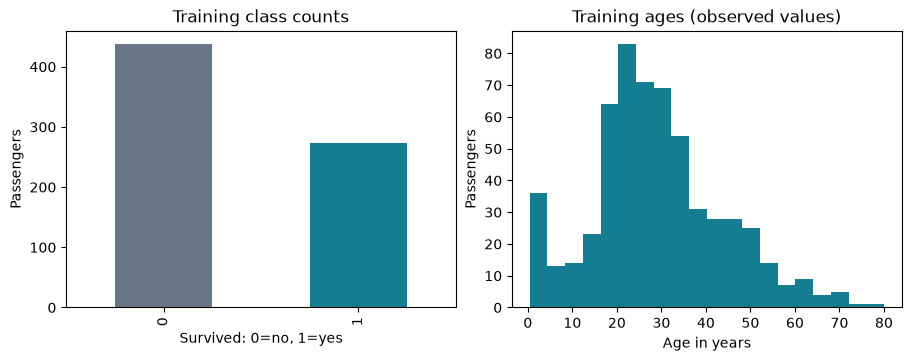

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
y_train.value_counts().sort_index().plot.bar(ax=axes[0], color=["#687787", "#147d92"])
axes[0].set(title="Training class counts", xlabel="Survived: 0=no, 1=yes", ylabel="Passengers")
train_df.Age.dropna().plot.hist(ax=axes[1], bins=20, color="#147d92")
axes[1].set(title="Training ages (observed values)", xlabel="Age in years", ylabel="Passengers")
fig.savefig(REPORTS / "figures" / "data_overview.png", dpi=150)
if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)

## 8. Train Naive Bayes and Logistic Regression
GaussianNB uses Bayes' rule and assumes independent Gaussian features within each
class. Counts and encoded categories are not Gaussian, so this is an approximation.
Logistic Regression applies a sigmoid to a weighted feature sum to estimate
survival probability. It assumes linear log-odds.
Both models use default settings; max_iter only gives LR enough time to converge.

In [8]:
models = {"Naive Bayes": GaussianNB(),
          "Logistic Regression": LogisticRegression(max_iter=1000)}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "training complete")

Naive Bayes training complete
Logistic Regression training complete


## 9. Compare results
Accuracy measures overall correctness. Precision measures correctness among
predicted survivors. Recall measures how many actual survivors were found.
F1 balances precision and recall. ROC-AUC evaluates probability ranking;
log-loss penalizes wrong, confident probabilities. Use threshold 0.5.
A majority-class prediction provides a basic accuracy reference.

In [9]:
majority_class = y_train.mode().iloc[0]
baseline_accuracy = accuracy_score(y_test, np.full(len(y_test), majority_class))
print(f"Majority-class baseline accuracy: {baseline_accuracy:.3f}")
rows, predictions, matrices = [], {}, {}
for name, model in models.items():
    probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
    predicted = (probability >= 0.5).astype(int)
    predictions[name] = predicted
    matrices[name] = confusion_matrix(y_test, predicted, labels=[0, 1]).tolist()
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, predicted),
                 "Precision": precision_score(y_test, predicted, zero_division=0),
                 "Recall": recall_score(y_test, predicted, zero_division=0),
                 "F1": f1_score(y_test, predicted, zero_division=0),
                 "ROC-AUC": roc_auc_score(y_test, probability),
                 "Log-loss": log_loss(y_test, np.column_stack([1-probability, probability]), labels=[0, 1])})
results = pd.DataFrame(rows).set_index("Model")
print(results.round(4).to_string())
results.to_csv(REPORTS / "results.csv")

Majority-class baseline accuracy: 0.620
                     Accuracy  Precision  Recall      F1  ROC-AUC  Log-loss
Model                                                                      
Naive Bayes            0.7877     0.7206  0.7206  0.7206   0.8409    0.6546
Logistic Regression    0.8045     0.7538  0.7206  0.7368   0.8650    0.4342


## 10. Confusion matrices
Rows = true labels, columns = predictions. Top-left: true negatives; top-right:
false positives; bottom-left: false negatives; bottom-right: true positives.

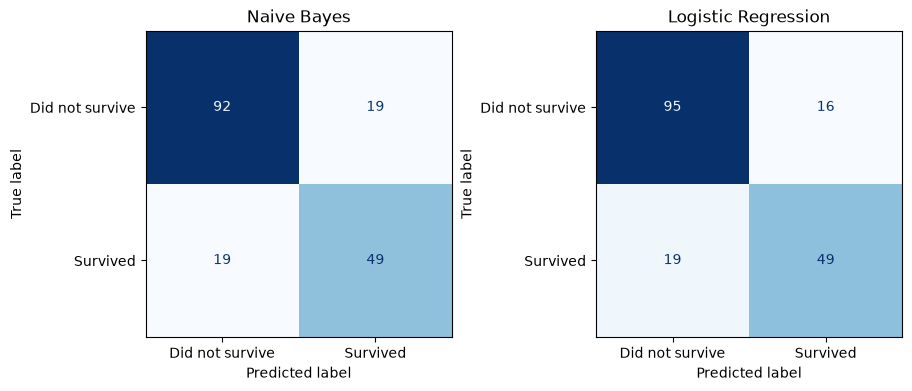

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), layout="constrained")
for ax, (name, predicted) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=[0, 1], display_labels=["Did not survive", "Survived"],
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
fig.savefig(REPORTS / "figures" / "confusion_matrices.png", dpi=150)
if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)

## 11. Interpret the results
Higher accuracy/F1 is better; lower log-loss is better. A single split cannot
prove that one algorithm is always superior. Correlation and non-Gaussian inputs
can challenge NB, while LR is limited to linear log-odds. Sex and class are
historical associations, not evidence of causal effects.

In [11]:
agreement = int((predictions["Naive Bayes"] == predictions["Logistic Regression"]).sum())
nb, lr = results.loc["Naive Bayes"], results.loc["Logistic Regression"]
conclusion = (
    f"Naive Bayes: accuracy {nb['Accuracy']:.3f}, F1 {nb['F1']:.3f}, log-loss {nb['Log-loss']:.3f}.\n"
    f"Logistic Regression: accuracy {lr['Accuracy']:.3f}, F1 {lr['F1']:.3f}, log-loss {lr['Log-loss']:.3f}.\n"
    f"The models agreed on {agreement} of {len(y_test)} test passengers.\n"
    f"Highest accuracy in this run: {results['Accuracy'].idxmax()}.\n"
    "These results apply to this split and preprocessing. No parameter tuning was done in this notebook."
)
print(conclusion)
summary = {"train_records": len(y_train), "test_records": len(y_test),
           "majority_baseline_accuracy": baseline_accuracy,
           "confusion_matrices": matrices, "agreement": agreement}
(REPORTS / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
report = f"""# Titanic classification assignment

## Objective and dataset
Compare Gaussian Naive Bayes and Logistic Regression on Kaggle Titanic data.
Source: https://www.kaggle.com/competitions/titanic/data (subject to competition rules).
The labeled train.csv has 891 passengers, 12 columns, 342 survivors and 549 non-survivors.
Positive class: Survived=1. Kaggle's unlabeled test.csv is not used.

## Data preparation
Missing: Age 177, Cabin 687, Embarked 2. No complete duplicate records were found.
Use Age, SibSp, Parch, Fare, Pclass, Sex and Embarked. Exclude identity/detail fields
PassengerId, Name, Ticket and Cabin. Keep zero/extreme fares because they are not proven errors.
Reuse the fixed travel-group-separated split: {len(y_train)} train / {len(y_test)} test.
Fill numeric gaps with training medians, categorical gaps with training modes.
Encode using training categories and scale numeric values using training statistics.
No oversampling, feature search, parameter search or threshold tuning is used.

## Models and measures
GaussianNB assumes class-conditional independent Gaussian features; counts and
categorical indicators violate that approximation. LR estimates sigmoid probabilities
with linear log-odds. Both use defaults; LR max_iter=1000 allows convergence.
Accuracy=(TP+TN)/N; precision=TP/(TP+FP); recall=TP/(TP+FN);
F1=2TP/(2TP+FP+FN). Undefined precision/recall use zero_division=0.
ROC-AUC uses probabilities; log-loss measures probability confidence.

## Results
Majority-class baseline accuracy: {baseline_accuracy:.3f}.

```text
{results.round(4).to_string()}
```

![Confusion matrices](figures/confusion_matrices.png)

## Discussion
{conclusion}

Related predictors can challenge NB's conditional independence assumption. LR permits
correlated predictors but uses linear log-odds. Ranking and threshold metrics may favor
different models. These observations do not establish a causal explanation for differences.
The small historical sample and one split limit generalization. Travel groups are
imperfect proxies for companions. The test partition was evaluated in earlier development;
this simplified default-model comparison is not a new independent experiment.
No setting was adjusted to improve these test scores.

## Reproduction and references
Run `python assignment.py` or execute `notebooks/assignment.ipynb` from top to bottom.
Tables, plots and this report are generated from real results.
- Data/rules: https://www.kaggle.com/competitions/titanic/data and https://www.kaggle.com/competitions/titanic/rules
- NB: https://scikit-learn.org/stable/modules/naive_bayes.html
- LR: https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
"""
(REPORTS / "assignment_report.md").write_text(report, encoding="utf-8")

Naive Bayes: accuracy 0.788, F1 0.721, log-loss 0.655.
Logistic Regression: accuracy 0.804, F1 0.737, log-loss 0.434.
The models agreed on 168 of 179 test passengers.
Highest accuracy in this run: Logistic Regression.
These results apply to this split and preprocessing. No parameter tuning was done in this notebook.


3228